# Base model: which moments do people replay?

**Goal.** Learn, from YouTube "Most replayed" curves, which 15-second moments in a song people return to.
New users get these picks before the personal model knows their taste.

**How to read this notebook.** One section per research step. Each ends with a **Verdict** line.

| # | Step | Question | Status |
|---|---|---|---|
| 1 | Data | Is the data good enough? | ✅ done |
| 2 | Explore | Is there a pattern at all? | next |
| 3 | Baselines | How good are simple rules? | |
| 4 | Train | Can the model learn? | |
| 5 | Evaluate | Does it beat the simple rules on unseen songs? | |
| 6 | Tune | Can better settings help? | |
| 7 | Understand | What did it learn? | |
| 8 | Decide | Keep it or drop it? | |

Research only: YouTube data is not cleared for a product model.

In [1]:
import json
from collections import Counter
import matplotlib.pyplot as plt
from musicdna.corpus.genre_mix import GenreMixManifest, GENRES, TIERS, OPENING_SEC

# Reference palette (dataviz skill): blue = has a replay curve, light grey = none.
HAS, NONE, INK, MUTED, GRID = '#2a78d6', '#d6d5d0', '#0b0b0b', '#52514e', '#e7e6e1'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

manifest = GenreMixManifest.load()
songs = manifest.entries
with_curve = [s for s in songs if s.replay_curve]
print(f'{len(songs)} songs, {len(with_curve)} with a replay curve, {sum(bool(s.audio_file) for s in songs)} downloaded')

120 songs, 92 with a replay curve, 120 downloaded


## Step 1 · Data

**Question:** does every genre have enough songs with a replay curve?

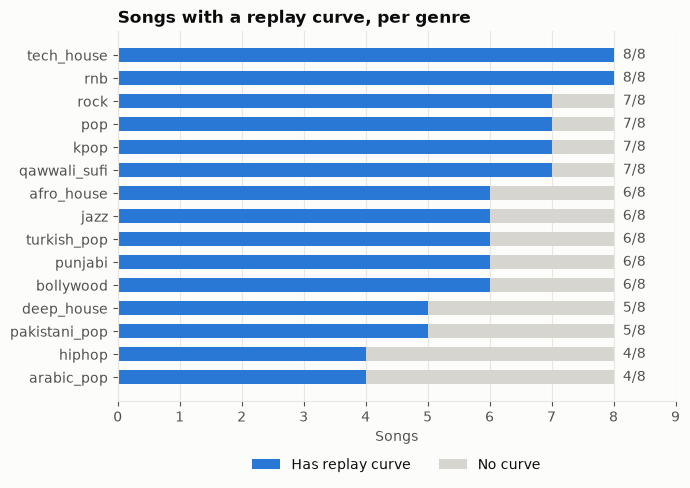

In [2]:
genres = sorted(GENRES, key=lambda g: sum(1 for s in with_curve if s.genre == g))
has = [sum(1 for s in with_curve if s.genre == g) for g in genres]
total = [sum(1 for s in songs if s.genre == g) for g in genres]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(genres, has, color=HAS, height=0.62, label='Has replay curve')
ax.barh(genres, [t - h for t, h in zip(total, has)], left=has, color=NONE, height=0.62, label='No curve')
for y, (h, t) in enumerate(zip(has, total)):
    ax.text(t + 0.15, y, f'{h}/{t}', va='center', color=MUTED)
ax.set_xlim(0, 9); ax.set_xlabel('Songs')
ax.set_title('Songs with a replay curve, per genre', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2); ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

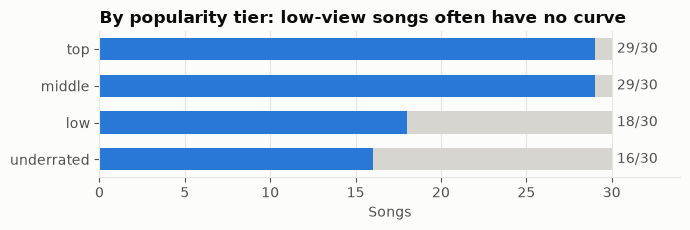

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.4))
has_t = [sum(1 for s in with_curve if s.tier == t) for t in TIERS]
tot_t = [sum(1 for s in songs if s.tier == t) for t in TIERS]
ax.barh(TIERS[::-1], has_t[::-1], color=HAS, height=0.6)
ax.barh(TIERS[::-1], [t - h for t, h in zip(tot_t, has_t)][::-1], left=has_t[::-1], color=NONE, height=0.6)
for y, (h, t) in enumerate(zip(has_t[::-1], tot_t[::-1])):
    ax.text(t + 0.3, y, f'{h}/{t}', va='center', color=MUTED)
ax.set_xlim(0, 34); ax.set_xlabel('Songs')
ax.set_title('By popularity tier: low-view songs often have no curve', loc='left', fontweight='bold')
ax.grid(axis='x', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**What a replay curve looks like.** One song per region. The curve is 1.0 at the most replayed moment of that video.
The grey band is the opening, where every view starts, so it is high in every song and is ignored.

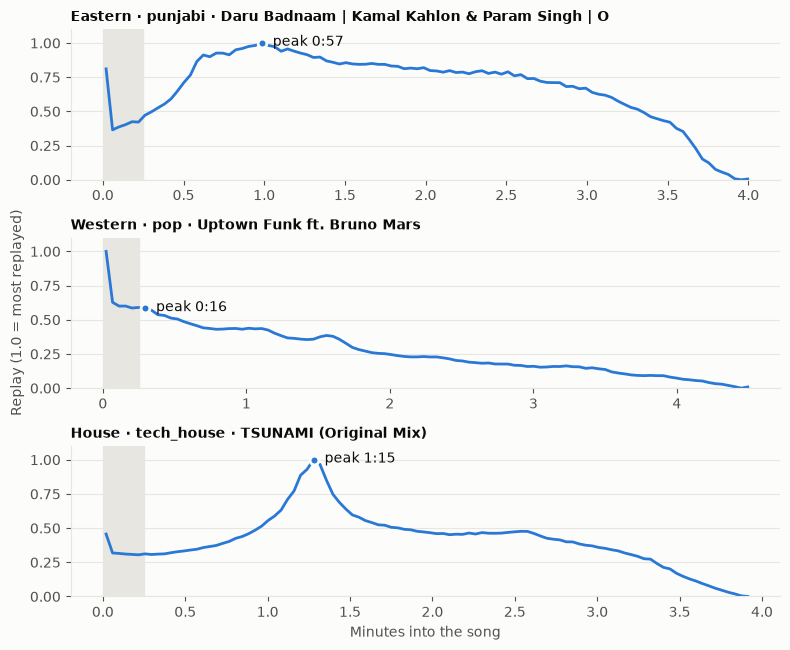

In [4]:
def example(region):
    pool = [s for s in with_curve if s.region == region and s.tier == 'top']
    return max(pool, key=lambda s: s.view_count)

fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharey=True)
for ax, region in zip(axes, ['eastern', 'western', 'house']):
    s = example(region)
    x = [(a + b) / 2 / 60 for a, b, _ in s.replay_curve]
    y = [v for *_, v in s.replay_curve]
    after = [seg for seg in s.replay_curve if seg[0] >= OPENING_SEC]
    peak = max(after, key=lambda seg: seg[2])
    ax.axvspan(0, OPENING_SEC / 60, color=GRID)
    ax.plot(x, y, color=HAS, lw=2)
    ax.scatter([(peak[0] + peak[1]) / 2 / 60], [peak[2]], s=40, color=HAS, edgecolor='#fcfcfb', lw=2, zorder=3)
    m, sec = divmod(int(peak[0]), 60)
    ax.annotate(f'peak {m}:{sec:02d}', ((peak[0] + peak[1]) / 2 / 60, peak[2]), xytext=(8, -2),
                textcoords='offset points', color=INK)
    ax.set_title(f'{region.title()} · {s.genre} · {s.song[:45]}', loc='left', fontsize=10, fontweight='bold')
    ax.set_ylim(0, 1.1); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
axes[-1].set_xlabel('Minutes into the song'); axes[1].set_ylabel('Replay (1.0 = most replayed)')
plt.tight_layout(); plt.show()

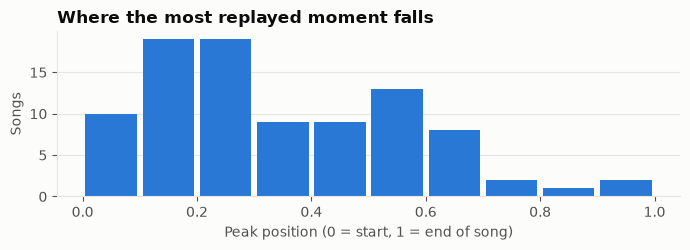

62% of peaks fall in the first 40% of the song


In [5]:
# Where do peaks fall? Position of each song's peak (after the opening), as a share of song length.
positions = []
for s in with_curve:
    after = [seg for seg in s.replay_curve if seg[0] >= OPENING_SEC]
    peak = max(after, key=lambda seg: seg[2])
    positions.append(peak[0] / s.replay_curve[-1][1])
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(positions, bins=10, range=(0, 1), color=HAS, rwidth=0.9)
ax.set_xlabel('Peak position (0 = start, 1 = end of song)'); ax.set_ylabel('Songs')
ax.set_title('Where the most replayed moment falls', loc='left', fontweight='bold')
ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
early = sum(p < 0.4 for p in positions) / len(positions)
print(f'{early:.0%} of peaks fall in the first 40% of the song')

**Verdict (Step 1):** see the summary printed below. Every genre needs at least 4 songs with curves for a fair per-genre test.

In [6]:
per_genre = {g: sum(1 for s in with_curve if s.genre == g) for g in GENRES}
weakest = min(per_genre, key=per_genre.get)
ok = all(v >= 4 for v in per_genre.values())
print(f'{len(with_curve)}/{len(songs)} songs have curves. Weakest genre: {weakest} ({per_genre[weakest]}).')
print('PASS: every genre has at least 4 songs with curves.' if ok else 'FAIL: some genres have fewer than 4.')

92/120 songs have curves. Weakest genre: arabic_pop (4).
PASS: every genre has at least 4 songs with curves.


## Step 2 · Explore *(next)*

**Question:** do replay peaks line up with the sound (energy, loudness, brightness), or only with song position?
Needs the DSP + CLAP features, which are being computed.